# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
# Step 1: Import libraries and load data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

df = pd.read_csv("car_purchase_data.csv")

print("Shape:", df.shape)
display(df.head())
df.info()
print("\nClass balance (Purchased):")
print(df["Purchased"].value_counts())

Shape: (400, 5)


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   User ID    400 non-null    int64
 1   Gender     400 non-null    str  
 2   Age        400 non-null    int64
 3   Salary     400 non-null    int64
 4   Purchased  400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB

Class balance (Purchased):
Purchased
0    257
1    143
Name: count, dtype: int64


### Step 2: Split features and target

In [2]:
# Step 2: Split features (X) and target (y)
# Only Age and Salary are used as features; User ID is just an identifier and Gender is not part of this task.
X = df[["Age", "Salary"]].values
y = df["Purchased"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 2)
y shape: (400,)


### Step 3: Train/Test Split

In [3]:
# Step 3: Train/Test Split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (300, 2) | Test set: (100, 2)


### Step 4: Feature Scaling

In [4]:
# Step 4: Feature Scaling
# Age (~18-60) and Salary (~15,000-150,000) are on very different scales, so we standardize them.
# The scaler is fit on the training data only, then applied to the test data (avoids data leakage).
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print("Scaled training data (first 5 rows):")
print(X_train_scaled[:5])

Scaled training data (first 5 rows):
[[ 0.58164944 -0.88670699]
 [-0.60673761  1.46173768]
 [-0.01254409 -0.5677824 ]
 [-0.60673761  1.89663484]
 [ 1.37390747 -1.40858358]]


### Step 5: Train Logistic Regression Model

In [5]:
# Step 5: Train Logistic Regression Model
classifier = LogisticRegression(random_state=0)
classifier.fit(X_train_scaled, y_train)

print("Coefficients (Age, Salary):", classifier.coef_)
print("Intercept:", classifier.intercept_)

Coefficients (Age, Salary): [[2.07665837 1.11008221]]
Intercept: [-0.95217247]


### Step 6: Predict and Evaluate

Accuracy: 0.8900 (89.00%)

Confusion Matrix:
[[65  3]
 [ 8 24]]

Classification Report:
                   precision    recall  f1-score   support

Not Purchased (0)       0.89      0.96      0.92        68
    Purchased (1)       0.89      0.75      0.81        32

         accuracy                           0.89       100
        macro avg       0.89      0.85      0.87       100
     weighted avg       0.89      0.89      0.89       100



,Age,Salary,P(Purchased=1),Predicted,Actual
0,30.0,87000.0,0.113,0,0
1,38.0,50000.0,0.167,0,0
2,35.0,75000.0,0.195,0,0
3,30.0,79000.0,0.089,0,0
4,35.0,50000.0,0.097,0,0


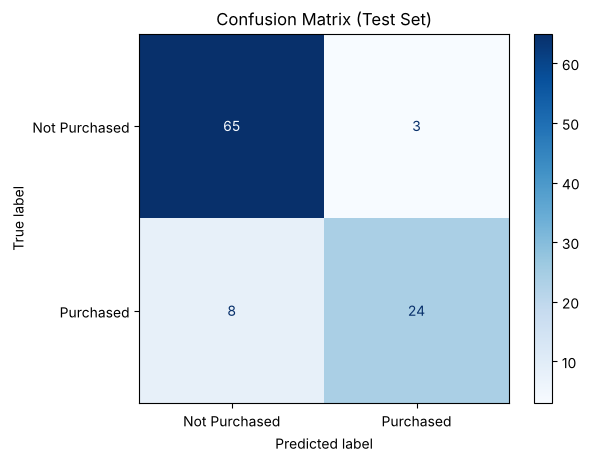

In [6]:
# Step 6: Predict and Evaluate
y_pred = classifier.predict(X_test_scaled)
y_prob = classifier.predict_proba(X_test_scaled)[:, 1]   # probability of Purchased = 1

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Not Purchased (0)", "Purchased (1)"]))

# Example: probability -> class (threshold = 0.5)
sample = pd.DataFrame({
    "Age": sc.inverse_transform(X_test_scaled)[:5, 0].round(),
    "Salary": sc.inverse_transform(X_test_scaled)[:5, 1].round(),
    "P(Purchased=1)": y_prob[:5].round(3),
    "Predicted": y_pred[:5],
    "Actual": y_test[:5],
})
display(sample)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Purchased", "Purchased"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.show()

### Step 7: Visualization of Decision Regions

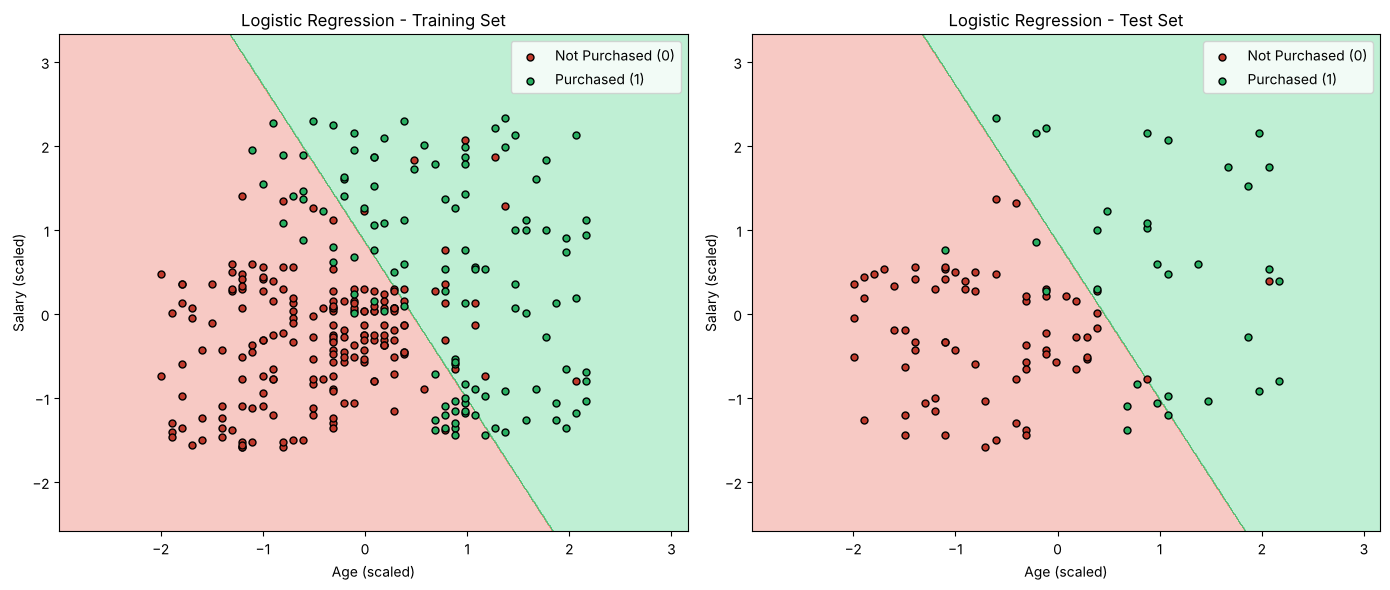

In [7]:
# Step 7: Visualization of Decision Regions (training set and test set)
def plot_decision_regions(X_set, y_set, title, ax):
    X1, X2 = np.meshgrid(
        np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.01),
        np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.01),
    )
    Z = classifier.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)
    ax.contourf(X1, X2, Z, alpha=0.3, cmap=ListedColormap(["#e74c3c", "#2ecc71"]))
    for label, color, name in [(0, "#c0392b", "Not Purchased (0)"), (1, "#27ae60", "Purchased (1)")]:
        ax.scatter(X_set[y_set == label, 0], X_set[y_set == label, 1],
                   c=color, edgecolor="k", s=25, label=name)
    ax.set_title(title)
    ax.set_xlabel("Age (scaled)")
    ax.set_ylabel("Salary (scaled)")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_decision_regions(X_train_scaled, y_train, "Logistic Regression - Training Set", axes[0])
plot_decision_regions(X_test_scaled, y_test, "Logistic Regression - Test Set", axes[1])
plt.tight_layout()
plt.show()

## IV. Reflection Questions 
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


## Objective Understanding

**Goal & rationale:** The goal of this assignment is to predict whether a customer will purchase a car (`Purchased` = 1) or not (`Purchased` = 0) based on two features: `Age` and `Salary`. A model like this could help a car dealer target customers who are most likely to buy, instead of spending marketing effort on everyone.

**Why logistic regression:** The target variable is binary (yes/no), so this is a **binary classification** problem, not a regression problem. Linear regression would produce values outside the 0–1 range, which cannot be interpreted as probabilities. Logistic regression passes a linear combination of the features through the **sigmoid function**, σ(z) = 1 / (1 + e^(−z)), which always outputs a value between 0 and 1 — the probability of purchase. It is also simple, fast, and interpretable (the sign and size of each coefficient show how each feature affects the purchase probability), which makes it a good baseline for a small dataset with two numeric features.

---

## Reflection Answers

**1. Logistic regression outputs probabilities — why can it still be used for classification?**

Logistic regression outputs P(Purchased = 1 | Age, Salary), a value between 0 and 1. To turn this probability into a class label, we apply a **decision threshold** (0.5 by default): if the probability is ≥ 0.5 the customer is classified as 1 (Purchased), otherwise as 0 (Not Purchased). Since σ(z) = 0.5 exactly when z = 0, the threshold corresponds to a straight line (the **decision boundary**) β₀ + β₁·Age + β₂·Salary = 0 in feature space, which splits the space into two classes. This is the straight boundary between the red and green regions in the Step 7 plot. The threshold can also be adjusted (e.g., lowered to catch more buyers) depending on whether false positives or false negatives are more costly.

**2. Based on your model, which customers are more likely to purchase a car?**

Both coefficients are positive (Age ≈ 2.08, Salary ≈ 1.11 on the standardized scale), so the probability of purchase increases with both age and salary. Age has the larger coefficient, so it is the stronger predictor. In practice, **older customers (roughly 45+) are likely to buy even with a lower salary**, and **younger customers are likely to buy only if they have a high salary** (roughly above $100,000). Young customers with low or medium salaries are the least likely to purchase. In the decision region plot, the "Purchased" (green) region is the upper-right part of the graph.

**3. What factors might cause low accuracy in this task?**

- **Linear decision boundary:** Logistic regression can only draw a straight line, but the true pattern is not perfectly linear (e.g., some older customers with low salaries still buy). Points near the boundary are misclassified.
- **Limited features:** Only Age and Salary are used; buying a car also depends on things like existing car ownership, family size, credit score, and location.
- **Small dataset:** With only 400 rows (100 in the test set), each misclassified point changes accuracy by 1%, and results can vary with the random split.
- **Class imbalance:** About 64% of customers did not purchase, so the model may be biased toward predicting class 0.
- **Not scaling the features:** Without scaling, Salary (tens of thousands) would dominate Age, which hurts the optimization and regularization.

**4. Propose additional features or preprocessing steps that could improve accuracy.**

- **Additional features:** encode `Gender` (one-hot / label encoding) and test whether it helps; collect other information such as credit score, current car ownership, number of dependents, location, or employment status.
- **Polynomial / interaction features:** add Age², Salary², and Age×Salary to allow a curved decision boundary while still using logistic regression.
- **Hyperparameter tuning:** tune the regularization strength `C` with **cross-validation** (`GridSearchCV`), and use k-fold cross-validation for a more reliable accuracy estimate than a single split.
- **Threshold tuning / class weights:** adjust the 0.5 threshold or use `class_weight="balanced"` to deal with class imbalance.
- **Try non-linear models** for comparison, such as K-Nearest Neighbors, SVM with an RBF kernel, or Random Forest.
